# 04 · Opening the black box: what drives a car's price in Jordan?

A good score is not enough: we want to know **why** the model predicts a price.
**SHAP** (SHapley Additive exPlanations) splits every single prediction into the contribution of each feature:

$$\log(\text{price}) = \text{base} + \phi_{\text{age}} + \phi_{\text{brand}} + \phi_{\text{mileage}} + \dots$$

Because we model log-price, each contribution is a **multiplier**: $e^{\phi}-1$ is the % effect
(e.g. $\phi=-0.30$ → about **−26%**). The idea comes from game theory: features are "players" sharing the prediction fairly.

We analyse the **test set** (cars the model never trained on). The model is final — nothing here changes it.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from jocars.cleaning import clean
from jocars.config import FIGURES, ROOT
from jocars.data import load_raw
from jocars.features import add_features, split_xy, train_test
from jocars.predict import explain_price, load_model
from jocars.plotting import SEQ, SERIES, TEXT_2, jod, set_style

set_style()
model = load_model()
_, test = train_test(add_features(clean(load_raw())))
X_test, y_test = split_xy(test)

# LightGBM computes exact TreeSHAP values itself (pred_contrib=True); last column = base value
contrib = model[-1].predict(model[:-1].transform(X_test), pred_contrib=True)
shap_df = pd.DataFrame(contrib[:, :-1], columns=X_test.columns, index=X_test.index)
base = contrib[0, -1]
print(f"base (average) price: {np.exp(base):,.0f} JOD   test cars: {len(X_test):,}")

base (average) price: 10,121 JOD   test cars: 1,774


## 1 · Which features matter most overall?

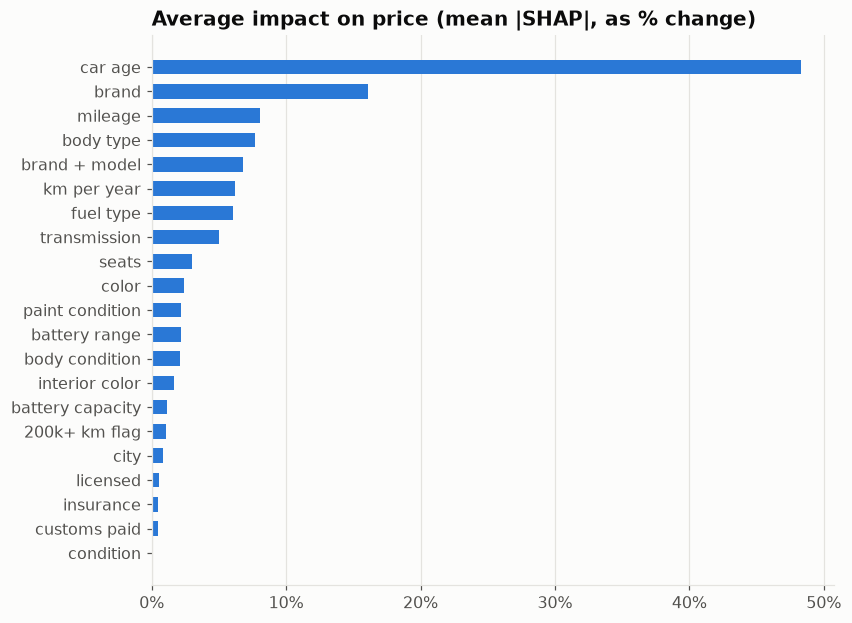

In [2]:
imp = shap_df.abs().mean().sort_values()
labels = {"car_age": "car age", "make_model": "brand + model", "make": "brand", "mileage_km": "mileage",
          "km_per_year": "km per year", "fuel_type": "fuel type", "body_type": "body type",
          "feat_carcustoms": "customs paid", "feat_battery_capacity": "battery capacity",
          "feat_battery_range": "battery range", "feat_paintcondition": "paint condition",
          "feat_body_condition": "body condition", "feat_insurance": "insurance",
          "feat_license": "licensed", "interior_color": "interior color",
          "mileage_200k_plus": "200k+ km flag"}
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh([labels.get(c, c) for c in imp.index], np.exp(imp.values) - 1, color=SEQ, height=0.6)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.set_title("Average impact on price (mean |SHAP|, as % change)")
fig.savefig(FIGURES / "fig12_feature_importance.png"); plt.show()

**Age** dominates (≈48% average impact), then **brand** (≈16%), then **mileage**, **body type**, the exact
**model**, **km per year** and **fuel type**. **Color** has only a small effect, and the **city** almost none once the car
itself is known — the Zarqa "premium" from the EDA was mostly *which cars* are sold there (correlation ≠ causation, confirmed!).

## 2 · How does age change the price? (and is it the same for EVs?)

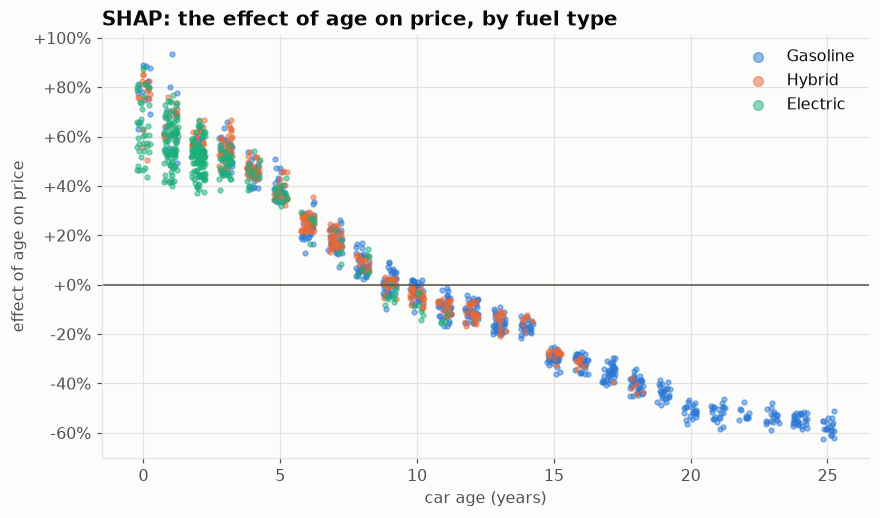

In [3]:
age = X_test["car_age"]
fuel = X_test["fuel_type"]
fig, ax = plt.subplots(figsize=(9, 5))
for color, f in zip(SERIES, ["Gasoline", "Hybrid", "Electric"]):
    m = (fuel == f) & (age <= 25)
    ax.scatter(age[m] + np.random.default_rng(0).uniform(-0.25, 0.25, m.sum()),
               np.exp(shap_df.loc[m, "car_age"]) - 1, s=10, alpha=0.5, color=color, label=f)
ax.axhline(0, color=TEXT_2, linewidth=1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("car age (years)"); ax.set_ylabel("effect of age on price")
ax.set_title("SHAP: the effect of age on price, by fuel type")
ax.legend(markerscale=2)
fig.savefig(FIGURES / "fig13_age_effect.png"); plt.show()

- A brand-new car gets a big premium; the curve falls fast in the **first ~5 years**, then flattens — that's classic depreciation.
- For **young cars (0–3 years)**, the age premium of **electric cars (green) is smaller** than for petrol and hybrid cars:
  a new EV loses a bigger share of its value in its first years (fast-moving battery tech, new models every year).
  The model *learned this "age × fuel type" interaction by itself* — exactly what a linear model couldn't do.

## 3 · One car, explained

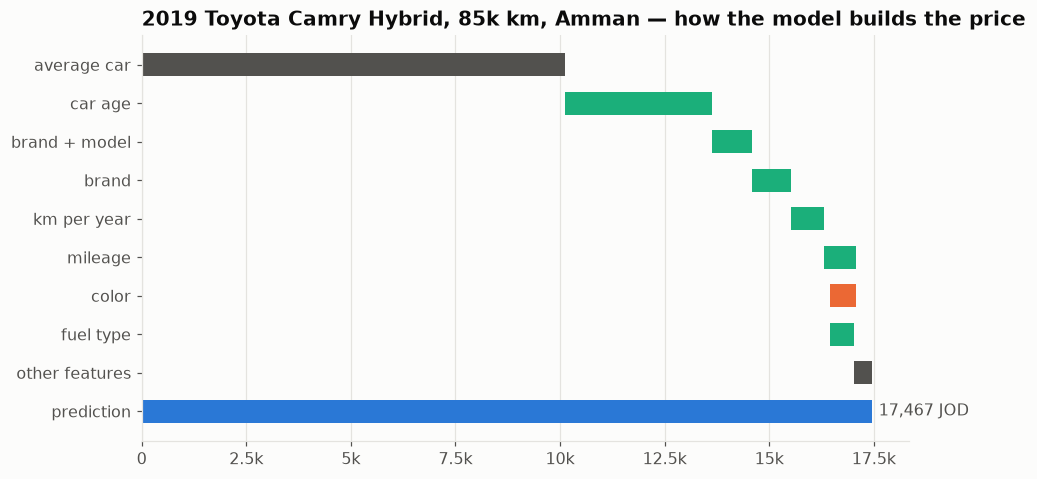

car age            +34.7%
brand + model       +7.0%
brand               +6.4%
km per year         +5.0%
mileage             +4.7%
color               -3.7%
fuel type           +3.5%


In [4]:
car = {"make": "Toyota", "model": "Camry", "year": "2019", "mileage_km": 84999, "body_type": "Sedan",
       "condition": "Used", "transmission": "Automatic", "fuel_type": "Hybrid", "engine_type": "Hybrid",
       "color": "White", "interior_color": "Beige", "seats": "5", "city": "Amman",
       "feat_insurance": "Compulsory Insurance", "feat_carcustoms": "With Customs",
       "feat_license": "Licensed", "feat_paintcondition": "Original Paint",
       "feat_body_condition": "Excellent with no defects"}
e = explain_price(car, model)
c = pd.Series(e["contributions"]).sort_values(key=abs, ascending=False)
top = c.head(7)
steps = [e["base_price"]]
for v in top.values:
    steps.append(steps[-1] * np.exp(v))
final = e["base_price"] * np.exp(c.sum())

fig, ax = plt.subplots(figsize=(9, 4.8))
names = ["average car"] + [labels.get(n, n) for n in top.index] + ["other features", "prediction"]
lefts, widths, colors = [0], [steps[0]], [TEXT_2]
for i, v in enumerate(top.values):
    lo, hi = sorted([steps[i], steps[i + 1]])
    lefts.append(lo); widths.append(hi - lo); colors.append(SERIES[2] if v > 0 else SERIES[1])
lo, hi = sorted([steps[-1], final]); lefts.append(lo); widths.append(hi - lo); colors.append(TEXT_2)
lefts.append(0); widths.append(final); colors.append(SEQ)
y = np.arange(len(names))[::-1]
ax.barh(y, widths, left=lefts, color=colors, height=0.6)
ax.set_yticks(y, names); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(jod))
ax.text(final + 150, y[-1], f"{final:,.0f} JOD", va="center", color=TEXT_2)
ax.set_title("2019 Toyota Camry Hybrid, 85k km, Amman — how the model builds the price")
fig.savefig(FIGURES / "fig14_one_car_explained.png"); plt.show()
for n, v in top.items():
    print(f"{labels.get(n, n):18s} {np.exp(v)-1:+6.1%}")

Green bars push the price **up**, orange bars push it **down**, starting from the average listing.
This is what the app will show: not just a number, but **the reasons**.

## 4 · Where is the model reliable? (test set)

In [5]:
pred = np.exp(model.predict(X_test)); true = np.exp(y_test)
ape = pd.Series(np.abs(pred - true) / true, index=X_test.index)
seg = pd.DataFrame({"fuel type": X_test["fuel_type"], "condition": X_test["condition"], "ape": ape})
for col in ["fuel type", "condition"]:
    display(seg.groupby(col)["ape"].agg(median_error="median", cars="size")
              .query("cars >= 30").style.format({"median_error": "{:.1%}"}))

,median_error,cars
fuel type,,
Diesel,13.1%,84
Electric,9.5%,341
Gasoline,15.4%,839
Hybrid,9.5%,373
Mild Hybrid,12.0%,31
Plug-in - Hybrid,10.0%,105


,median_error,cars
condition,,
New,11.7%,139
Used,11.9%,1635


Knowing *where* a model is weaker is part of an honest project: segments with fewer listings or more price variety
(e.g. rare fuel types) are harder. That goes into the README's **limitations** section.